In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
def gaussian_mutation(individual, mutation_rate=0.05, sigma=0.1):
    mutated = individual.copy()
    mask = np.random.rand(len(mutated)) < mutation_rate
    
    mutated[mask] += np.random.normal(0, sigma, size=np.sum(mask))
    return mutated

def single_point_crossover(parent1, parent2):
    k = np.random.randint(1, len(parent1))
    
    child1 = np.concatenate([parent1[:k], parent2[k:]])
    child2 = np.concatenate([parent2[:k], parent1[k:]])
    return child1, child2

In [16]:
def rank_selection(combined_population, combined_scores, pop_size):
    # łączymy rodziców i dzieci, sortujemy i ucinamy do rozmiaru populacji - selekcja rankingowa
    sorted_indices = np.argsort(combined_scores)
    best_indices = sorted_indices[:pop_size]

    population = combined_population[best_indices]
    scores = combined_scores[best_indices]    

    return population, scores

def tournament_selection(population, scores, pop_size, k=3):
    new_population = []
    new_scores = []
    
    total_pool_size = len(population)
    
    for _ in range(pop_size):
        participants_idx = np.random.choice(total_pool_size, size=k, replace=False)
        winner_idx = participants_idx[np.argmin(scores[participants_idx])]
        
        new_population.append(population[winner_idx].copy())
        new_scores.append(scores[winner_idx])
        
    return np.array(new_population), np.array(new_scores)


def roulette_wheel_selection(population, scores, pop_size):
    # elitaryzm - najlepszy osobnik przechodzi
    best_idx = np.argmin(scores)
    elite_individual = population[best_idx].copy()
    elite_score = scores[best_idx]

    worst_score = np.max(scores)
    fitness = worst_score - scores + 1e-6 
    
    probabilities = fitness / np.sum(fitness)
    
    total_pool_size = len(population)
    selected_indices = np.random.choice(total_pool_size, size=pop_size-1, p=probabilities)
    
    new_population = population[selected_indices].copy()
    new_scores = scores[selected_indices].copy()

    final_population = np.vstack((elite_individual, new_population))
    final_scores = np.append(elite_score, new_scores)
    
    return final_population, final_scores

In [17]:
class EvolutionaryAlgorithm:
    def __init__(self, objective_func, mutation_op, crossover_op, selection_op, pop_size=100, num_dimensions=5, bounds=(-5.12, 5.12), crossover_prob=0.8, mutation_prob=0.1):
        self.objective_func = objective_func
        self.mutation_op = mutation_op
        self.crossover_op = crossover_op
        self.selection_op = selection_op
        self.pop_size = pop_size
        self.num_dimensions = num_dimensions
        self.bounds = bounds

        self.crossover_prob = crossover_prob
        self.mutation_prob = mutation_prob

        # Inicjalizacja populacji - losowanie z rozkładu jednostajnego z wybranego zakresu
        low, high = self.bounds
        self.population = np.random.uniform(low, high, size=(pop_size, num_dimensions))
        
    def train(self, generations=1000):
        scores = np.array([self.objective_func(ind) for ind in self.population])
        history_best = []
        history_all = []

        # warunek stopu to dana liczba iteracji
        for gen in range(generations):
            children = []

            # KRZYŻOWANIE
            # losowe parowanie
            indices = np.arange(self.pop_size)
            np.random.shuffle(indices)

            for i in range(0, self.pop_size - 1, 2):
                parent1 = self.population[indices[i]]
                parent2 = self.population[indices[i+1]]
                
                if np.random.rand() < self.crossover_prob:
                    child1, child2 = self.crossover_op(parent1, parent2)
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                    
                children.extend([child1, child2])

            # MUTACJA
            mutated_children = []
            for child in children:
                if np.random.rand() < self.mutation_prob:
                    mutated_children.append(self.mutation_op(child))
                else:
                    mutated_children.append(child)
            
            mutated_children = np.array(mutated_children)

            # EWALUACJA
            children_scores = np.array([self.objective_func(c) for c in mutated_children])

            # SELEKCJA
            combined_population = np.vstack((self.population, mutated_children))
            combined_scores = np.concatenate((scores, children_scores))
            self.population, scores = self.selection_op(combined_population, combined_scores, self.pop_size)

            best_current_score = np.min(scores)
            avg_current_score = np.mean(scores)
            
            history_best.append(best_current_score)
            history_all.append(scores.copy())
            
            if gen % 10 == 0:
                print(f"Generacja {gen}: Najlepszy = {best_current_score:.4f}, Średni = {avg_current_score:.4f}")
        
        best_idx = np.argmin(scores)
        best_individual = self.population[best_idx]
        best_score = scores[best_idx]
        
        return best_individual, best_score, history_best, history_all

In [18]:
def plot(history_all, hist_best):
    plt.figure(figsize=(10, 6))
    generations = len(history_all)
    
    for gen in range(generations):
        scores = history_all[gen]
        x_values = [gen] * len(scores)
        plt.scatter(x_values, scores, color='steelblue', alpha=0.1, s=15, edgecolors='none')

    plt.plot(hist_best, color='black', linewidth=1.5, label='Najlepszy wynik')

    plt.title("Wizualizacja całej populacji", fontsize=14)
    plt.xlabel("Generacja", fontsize=12)
    plt.ylabel("Wartość funkcji celu", fontsize=12)
    plt.legend(fontsize=12)
    plt.yscale('log')
    
    plt.grid(True, alpha=0.3)
    plt.show()

# Funkcja $x^2+y^2+2z^2$

In [19]:
def function_3d(x):
    return x[0]**2 + x[1]**2 + 2*x[2]**2

Generacja 0: Najlepszy = 7.1793, Średni = 59.5752
Generacja 10: Najlepszy = 0.1313, Średni = 0.4148
Generacja 20: Najlepszy = 0.0347, Średni = 0.0407
Generacja 30: Najlepszy = 0.0022, Średni = 0.0038
Generacja 40: Najlepszy = 0.0001, Średni = 0.0001
Generacja 50: Najlepszy = 0.0001, Średni = 0.0001
Generacja 60: Najlepszy = 0.0001, Średni = 0.0001
Generacja 70: Najlepszy = 0.0001, Średni = 0.0001
Generacja 80: Najlepszy = 0.0001, Średni = 0.0001
Generacja 90: Najlepszy = 0.0001, Średni = 0.0001

--- KONIEC EWOLUCJI ---
Znalezione optimum: [-0.00124146  0.0002533   0.00649797]
Wartość w tym punkcie: 8.605253121870074e-05


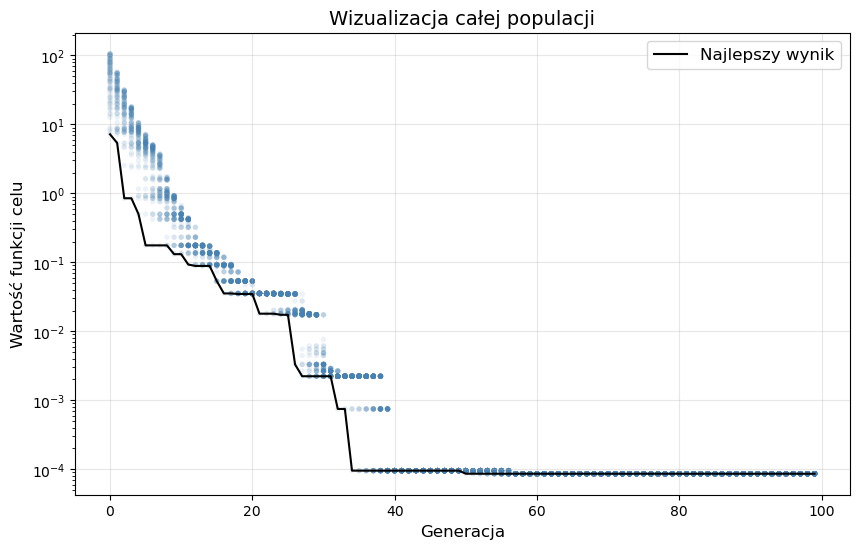

In [20]:
ea_3d = EvolutionaryAlgorithm(
    objective_func=function_3d, 
    mutation_op=gaussian_mutation, 
    crossover_op=single_point_crossover,
    selection_op=rank_selection,
    pop_size=100, 
    num_dimensions=3, 
    bounds=(-10.0, 10.0),
    crossover_prob=0.8,
    mutation_prob=0.1
)

best_solution_3d, best_value_3d, hist_best_3d, hist_all_3d = ea_3d.train(generations=100)

print("\n--- KONIEC EWOLUCJI ---")
print(f"Znalezione optimum: {best_solution_3d}")
print(f"Wartość w tym punkcie: {best_value_3d}")

plot(hist_all_3d, hist_best_3d)

Generacja 0: Najlepszy = 4.1090, Średni = 76.3990
Generacja 10: Najlepszy = 1.9975, Średni = 2.0298
Generacja 20: Najlepszy = 1.5658, Średni = 1.7070
Generacja 30: Najlepszy = 1.1031, Średni = 1.2161
Generacja 40: Najlepszy = 0.7977, Średni = 0.9510
Generacja 50: Najlepszy = 0.6918, Średni = 0.7074
Generacja 60: Najlepszy = 0.3503, Średni = 0.5302
Generacja 70: Najlepszy = 0.1755, Średni = 0.2941
Generacja 80: Najlepszy = 0.0090, Średni = 0.0572
Generacja 90: Najlepszy = 0.0016, Średni = 0.0017

--- KONIEC EWOLUCJI ---
Znalezione optimum: [-0.02507871 -0.00813948  0.00504086]
Wartość w tym punkcie: 0.0007460136024161554


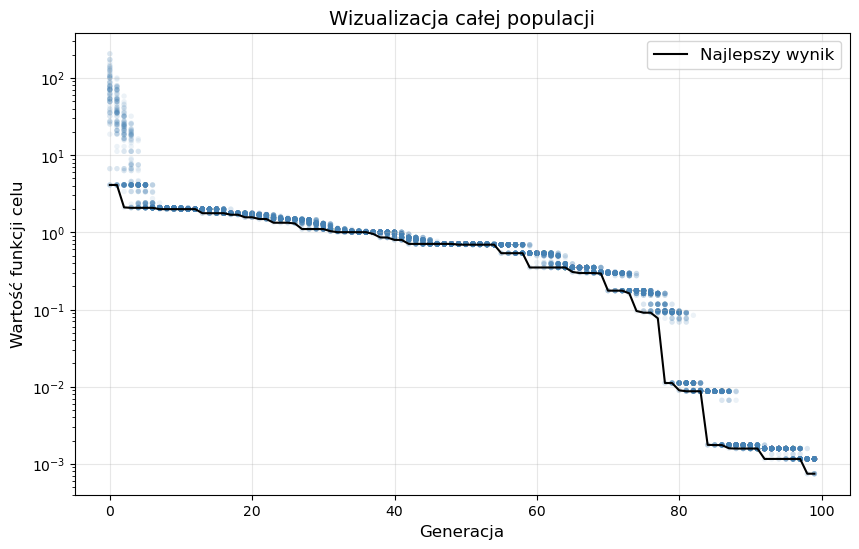

In [21]:
ea_3d = EvolutionaryAlgorithm(
    objective_func=function_3d, 
    mutation_op=gaussian_mutation, 
    crossover_op=single_point_crossover,
    selection_op=tournament_selection,
    pop_size=100, 
    num_dimensions=3, 
    bounds=(-10.0, 10.0),
    crossover_prob=0.8,
    mutation_prob=0.1
)

best_solution_3d, best_value_3d, hist_best_3d, hist_all_3d = ea_3d.train(generations=100)

print("\n--- KONIEC EWOLUCJI ---")
print(f"Znalezione optimum: {best_solution_3d}")
print(f"Wartość w tym punkcie: {best_value_3d}")

plot(hist_all_3d, hist_best_3d)

Generacja 0: Najlepszy = 10.5361, Średni = 105.7482
Generacja 10: Najlepszy = 2.1201, Średni = 8.5398
Generacja 20: Najlepszy = 2.0074, Średni = 2.3108
Generacja 30: Najlepszy = 1.5448, Średni = 1.8081
Generacja 40: Najlepszy = 1.2380, Średni = 1.3516
Generacja 50: Najlepszy = 0.6317, Średni = 0.9211
Generacja 60: Najlepszy = 0.5325, Średni = 0.6097
Generacja 70: Najlepszy = 0.1989, Średni = 0.2734
Generacja 80: Najlepszy = 0.0821, Średni = 0.1304
Generacja 90: Najlepszy = 0.0269, Średni = 0.0416

--- KONIEC EWOLUCJI ---
Znalezione optimum: [ 0.05291229  0.04975961 -0.03936582]
Wartość w tym punkcie: 0.00837506479381844


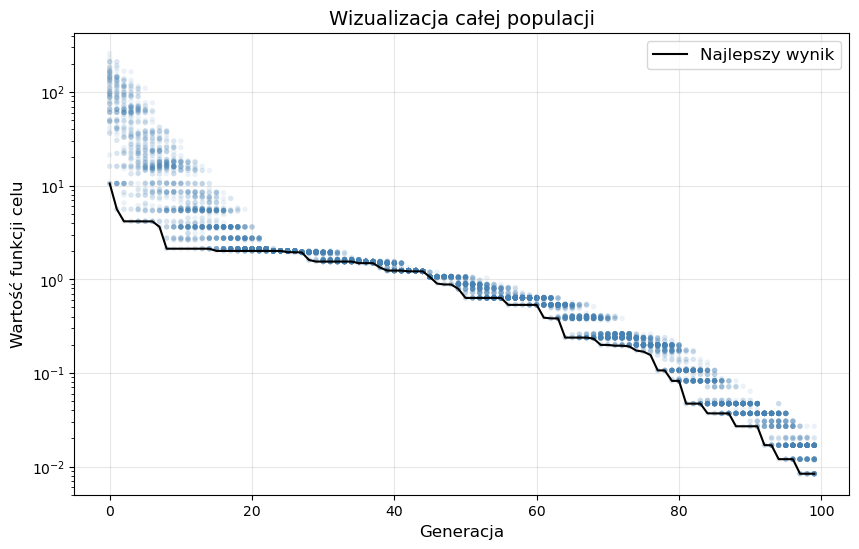

In [22]:
ea_3d = EvolutionaryAlgorithm(
    objective_func=function_3d, 
    mutation_op=gaussian_mutation, 
    crossover_op=single_point_crossover,
    selection_op=roulette_wheel_selection,
    pop_size=100, 
    num_dimensions=3, 
    bounds=(-10.0, 10.0),
    crossover_prob=0.8,
    mutation_prob=0.1
)

best_solution_3d, best_value_3d, hist_best_3d, hist_all_3d = ea_3d.train(generations=100)

print("\n--- KONIEC EWOLUCJI ---")
print(f"Znalezione optimum: {best_solution_3d}")
print(f"Wartość w tym punkcie: {best_value_3d}")

plot(hist_all_3d, hist_best_3d)

# Funkcja Rastrigina

In [23]:
def rastrigin(x, A=10):
    x = np.array(x)
    n = len(x)
    return A * n + np.sum(x**2 - A * np.cos(2 * np.pi * x))

Generacja 0: Najlepszy = 28.3325, Średni = 75.2666
Generacja 10: Najlepszy = 5.3672, Średni = 10.2630
Generacja 20: Najlepszy = 0.3108, Średni = 1.5059
Generacja 30: Najlepszy = 0.1266, Średni = 0.2949
Generacja 40: Najlepszy = 0.0568, Średni = 0.0768
Generacja 50: Najlepszy = 0.0118, Średni = 0.0396
Generacja 60: Najlepszy = 0.0055, Średni = 0.0078
Generacja 70: Najlepszy = 0.0038, Średni = 0.0054
Generacja 80: Najlepszy = 0.0034, Średni = 0.0038
Generacja 90: Najlepszy = 0.0034, Średni = 0.0034

--- KONIEC EWOLUCJI ---
Znalezione optimum: [-0.00349735  0.00104597  0.00161707  0.0010303   0.00012818]
Wartość w tym punkcie: 0.0033762023381314066


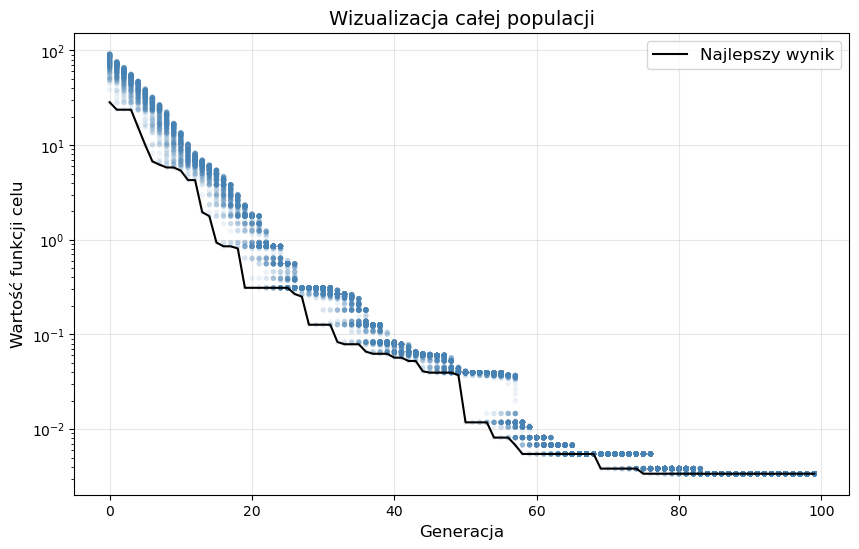

In [24]:
ea_rastrigin = EvolutionaryAlgorithm(
    objective_func=rastrigin, 
    mutation_op=gaussian_mutation, 
    crossover_op=single_point_crossover,
    selection_op=rank_selection,
    pop_size=200, 
    num_dimensions=5, 
    bounds=(-5.12, 5.12),
    crossover_prob=0.8,
    mutation_prob=0.2
)

best_solution_rastrigin, best_value_rastrigin, hist_best_rastrigin, hist_all_rastrigin = ea_rastrigin.train(generations=100)

print("\n--- KONIEC EWOLUCJI ---")
print(f"Znalezione optimum: {best_solution_rastrigin}")
print(f"Wartość w tym punkcie: {best_value_rastrigin}")

plot(hist_all_rastrigin, hist_best_rastrigin)

Generacja 0: Najlepszy = 40.3883, Średni = 74.3241
Generacja 10: Najlepszy = 8.8906, Średni = 11.7269
Generacja 20: Najlepszy = 3.1610, Średni = 4.0227
Generacja 30: Najlepszy = 1.2871, Średni = 1.6312
Generacja 40: Najlepszy = 1.1531, Średni = 1.1791
Generacja 50: Najlepszy = 1.1097, Średni = 1.1160
Generacja 60: Najlepszy = 1.0575, Średni = 1.0692
Generacja 70: Najlepszy = 1.0533, Średni = 1.0537
Generacja 80: Najlepszy = 1.0186, Średni = 1.0314
Generacja 90: Najlepszy = 1.0040, Średni = 1.0131

--- KONIEC EWOLUCJI ---
Znalezione optimum: [-9.95762000e-01  3.42261991e-03  3.14849429e-04  9.29346235e-05
 -1.49310812e-03]
Wartość w tym punkcie: 0.9978746474470626


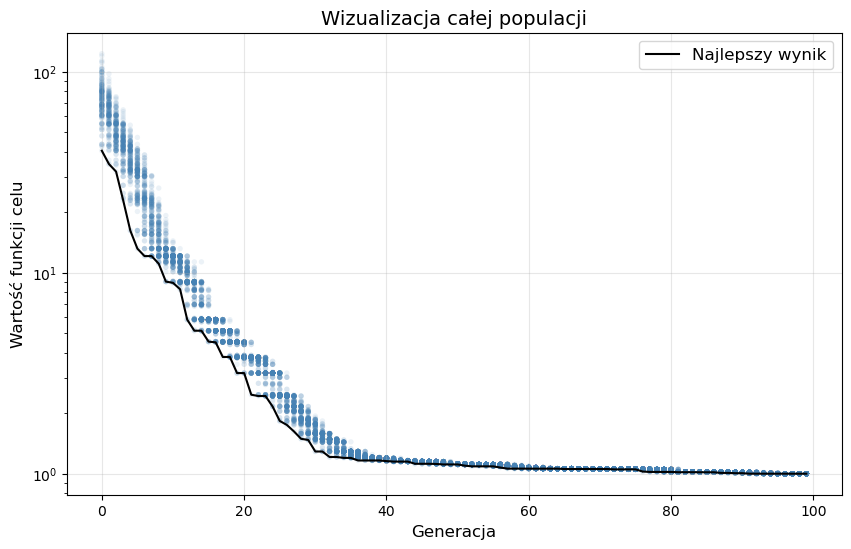

In [25]:
ea_rastrigin = EvolutionaryAlgorithm(
    objective_func=rastrigin, 
    mutation_op=gaussian_mutation, 
    crossover_op=single_point_crossover,
    selection_op=tournament_selection,
    pop_size=200, 
    num_dimensions=5, 
    bounds=(-5.12, 5.12),
    crossover_prob=0.8,
    mutation_prob=0.2
)

best_solution_rastrigin, best_value_rastrigin, hist_best_rastrigin, hist_all_rastrigin = ea_rastrigin.train(generations=100)

print("\n--- KONIEC EWOLUCJI ---")
print(f"Znalezione optimum: {best_solution_rastrigin}")
print(f"Wartość w tym punkcie: {best_value_rastrigin}")

plot(hist_all_rastrigin, hist_best_rastrigin)

Generacja 0: Najlepszy = 21.5493, Średni = 80.0327
Generacja 10: Najlepszy = 8.9454, Średni = 22.6361
Generacja 20: Najlepszy = 5.2526, Średni = 9.6429
Generacja 30: Najlepszy = 3.0637, Średni = 6.1359
Generacja 40: Najlepszy = 2.4067, Średni = 4.1342
Generacja 50: Najlepszy = 1.5463, Średni = 2.9608
Generacja 60: Najlepszy = 1.3054, Średni = 2.0866
Generacja 70: Najlepszy = 1.2145, Średni = 1.6443
Generacja 80: Najlepszy = 1.1712, Średni = 1.5565
Generacja 90: Najlepszy = 1.1034, Średni = 1.5277

--- KONIEC EWOLUCJI ---
Znalezione optimum: [-0.01624211 -0.00801895 -0.01366262 -0.00563307 -0.99560717]
Wartość w tym punkcie: 1.1033942569334414


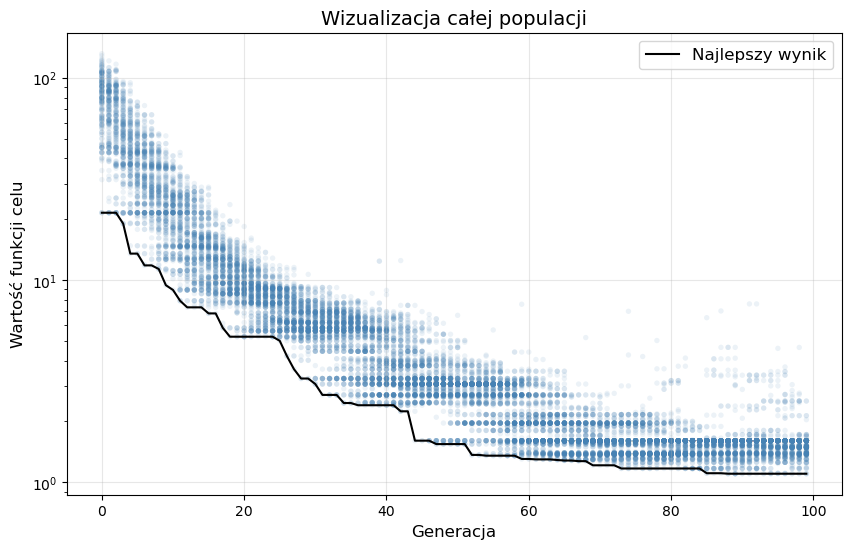

In [26]:
ea_rastrigin = EvolutionaryAlgorithm(
    objective_func=rastrigin, 
    mutation_op=gaussian_mutation, 
    crossover_op=single_point_crossover,
    selection_op=roulette_wheel_selection,
    pop_size=200, 
    num_dimensions=5, 
    bounds=(-5.12, 5.12),
    crossover_prob=0.8,
    mutation_prob=0.2
)

best_solution_rastrigin, best_value_rastrigin, hist_best_rastrigin, hist_all_rastrigin = ea_rastrigin.train(generations=100)

print("\n--- KONIEC EWOLUCJI ---")
print(f"Znalezione optimum: {best_solution_rastrigin}")
print(f"Wartość w tym punkcie: {best_value_rastrigin}")

plot(hist_all_rastrigin, hist_best_rastrigin)